# *Flaviviridae* glycoprotein fold trees: jackknife of the monophyly scores

How robust are the differences between the monophyly scores of the ESM3Di and AlphaFold2
trees of [flaviviridae_trees.ipynb](flaviviridae_trees.ipynb) to the choice of sequences?

**Method: paired delete-20% jackknife.** In each replicate a random 20% of the sequences is removed,
and the trees of both methods are rebuilt from the remaining 80%: the same subset for both,
so each replicate gives paired differences. 100 replicates per protein (E, E1, E2). The tips with an
unclassified code (..UN) are left out of the replicates, as of the scores in the figures: each is a group of its
own, whose position would otherwise decide part of the score.

The trees are rebuilt from the all-vs-all Foldseek results of `flaviviridae_trees.ipynb` with the
same steps as `esm3di foldtree` (distance matrix, QuickTree, negative branch lengths set to 0, MAD
rooting); 3Di prediction and Foldseek are not rerun. The search is exhaustive with `-e inf`, and a
pair's identity does not depend on the other sequences, so this equals rerunning the workflow on
the reduced set. Step 1 checks that the rebuild reproduces the workflow trees exactly.

**What it measures:** how much the scores and their differences depend on which sequences are in
the tree (taxon sampling). It does not capture uncertainty of the 3Di predictions or the
alignments, and replicates overlap in most of their sequences, so the percentile range is a
descriptive spread, not a confidence interval in the strict sense.

Run `flaviviridae_trees.ipynb` first. Results are cached in `RESULTS_CSV`; to recompute them, run on
a compute node and set `WORKERS` to the available cores. `flaviviridae_ultrametricity.ipynb` draws these replicates
in the figure `figures/flaviviridae_jackknife`.

In [1]:
import os
import tempfile
from pathlib import Path

import pandas as pd
from Bio import Phylo

from foldtree_resample import build_tree, jackknife, load_allvall
from monophyly import glycoprotein_labels, relabel_tree, score_monophyly

INPUT_DIR = Path("flaviviridae_inputs")
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/flaviviridae")    # esm3di foldtree runs of flaviviridae_trees.ipynb
RESULTS_CSV = Path("results/flaviviridae_jackknife.csv")

REPLICATES = 100
FRACTION = 0.8      # share of sequences kept per replicate
SEED = 1
WORKERS = min(16, os.cpu_count())

DATASETS = {"fullglyco_E": "E", "fullglyco_E1": "E1", "fullglyco_E2": "E2"}
MODELS = {"esm3di": "ESM3Di", "af2": "AlphaFold2"}

QUICKTREE = next(OUTPUT_DIR.glob(".snakemake_conda/*/bin/quicktree"))   # installed by esm3di foldtree
labels = glycoprotein_labels({
    "E": INPUT_DIR / "refolded_fullglyco_E_aa.fas",
    "E1": INPUT_DIR / "refolded_fullglyco_E1_aa.fas",
    "E2": INPUT_DIR / "refolded_fullglyco_E2_aa.fas",
})
allvall = {dataset: {model: load_allvall(OUTPUT_DIR / f"{model}_{dataset}" / "allvall_1.csv") for model in MODELS}
           for dataset in DATASETS}


def classified(table):
    """The all-vs-all table without the tips with an unclassified code."""
    unclassified = {name for name in set(table["query"]) if labels[name][4:6] == "UN"}
    return table[~table["query"].isin(unclassified) & ~table["target"].isin(unclassified)]

## 1. Check: the rebuild reproduces the workflow trees

With all sequences kept, every rebuilt tree must have the same rooted clades and the same score as
the tree written by `esm3di foldtree`.

In [2]:
def clades(path):
    return {frozenset(leaf.name for leaf in clade.get_terminals())
            for clade in Phylo.read(path, "newick").get_nonterminals()}


rows = []
for dataset in DATASETS:
    for model in MODELS:
        workflow_tree = OUTPUT_DIR / f"{model}_{dataset}" / f"{model}_struct_tree.PP.nwk.rooted"
        with tempfile.TemporaryDirectory() as workdir:
            rebuilt = build_tree(allvall[dataset][model], workdir, QUICKTREE)
            score = score_monophyly(relabel_tree(rebuilt, Path(workdir) / "rebuilt.nwk", labels), verbose=False)
            reference = score_monophyly(relabel_tree(workflow_tree, Path(workdir) / "workflow.nwk", labels),
                                        verbose=False)
            rows.append((DATASETS[dataset], MODELS[model], clades(rebuilt) == clades(workflow_tree),
                         score[0], reference[0], score[1]))
check = pd.DataFrame(rows, columns=["dataset", "method", "same_rooted_clades", "monophyletic_rebuilt",
                                    "monophyletic_workflow", "internal_nodes"])
assert check["same_rooted_clades"].all() and (check["monophyletic_rebuilt"] == check["monophyletic_workflow"]).all()
# Scores of the rebuilt trees of all classified sequences, the reference of the replicates
rows = []
for dataset in DATASETS:
    for model in MODELS:
        with tempfile.TemporaryDirectory() as workdir:
            rebuilt = build_tree(classified(allvall[dataset][model]), workdir, QUICKTREE)
            score = score_monophyly(relabel_tree(rebuilt, Path(workdir) / "rebuilt.nwk", labels), verbose=False)
            rows.append((DATASETS[dataset], MODELS[model], score[2]))
full_scores = pd.DataFrame(rows, columns=["dataset", "method", "fraction"])
check

,dataset,method,same_rooted_clades,monophyletic_rebuilt,monophyletic_workflow,internal_nodes
0,E,ESM3Di,True,213,213,246
1,E,AlphaFold2,True,216,216,246
2,E1,ESM3Di,True,180,180,189
3,E1,AlphaFold2,True,176,176,189
4,E2,ESM3Di,True,180,180,188
5,E2,AlphaFold2,True,180,180,188


## 2. Jackknife replicates

In [3]:
if RESULTS_CSV.exists():
    replicates = pd.read_csv(RESULTS_CSV)
    print(f"Loaded {len(replicates)} rows from {RESULTS_CSV}")
else:
    tables = []
    for dataset, name in DATASETS.items():
        print(f"{name}: {REPLICATES} replicates on {WORKERS} workers")
        table = jackknife({MODELS[m]: classified(allvall[dataset][m]) for m in MODELS}, labels, QUICKTREE,
                          replicates=REPLICATES, fraction=FRACTION, seed=SEED, workers=WORKERS)
        tables.append(table.assign(dataset=name))
    replicates = pd.concat(tables, ignore_index=True)
    RESULTS_CSV.parent.mkdir(exist_ok=True)
    replicates.to_csv(RESULTS_CSV, index=False)
replicates.head()

Loaded 600 rows from results/flaviviridae_jackknife.csv


,replicate,method,tips,monophyletic,internal_nodes,fraction,not_clades,root_to_tip_cv,best_root_cv,dataset
0,0,AlphaFold2,189,171,188,0.909574,E0FJAF;E0FJFL;E0FJJI;E0PLLG,0.040835,0.014011,E
1,0,ESM3Di,189,170,188,0.904255,E0FJAF;E0FJFL;E0FJJI;E0PLLG,0.010964,0.009508,E
2,1,AlphaFold2,189,173,188,0.920213,E0FJAF;E0FJFL;E0FJJI;E0PLLG,0.018386,0.010973,E
3,1,ESM3Di,189,168,188,0.893617,E0FJAF;E0FJFL;E0FJJI;E0PLLG,0.013342,0.009221,E
4,2,AlphaFold2,189,165,188,0.877660,E0FJAF;E0FJFL;E0FJJI;E0PLLG,0.057976,0.016564,E


## 3. Summary

Per protein: the full-data scores, the mean jackknife scores, and the paired differences of ESM3Di
from AlphaFold2 in the fraction of monophyletic internal nodes (mean, 2.5th–97.5th
percentile, and the share of replicates in which ESM3Di scores higher).

In [4]:
paired = replicates.pivot_table(index=["dataset", "replicate"], columns="method", values="fraction")
summary = []
for name in DATASETS.values():
    rows = paired.loc[name]
    full = full_scores[full_scores["dataset"] == name].set_index("method")["fraction"]
    for other in ("AlphaFold2",):
        d = rows["ESM3Di"] - rows[other]
        summary.append({
            "protein": name, "ESM3Di minus": other,
            "full ESM3Di": full["ESM3Di"], "full other": full[other],
            "jackknife ESM3Di": rows["ESM3Di"].mean(), "jackknife other": rows[other].mean(),
            "mean difference": d.mean(), "2.5%": d.quantile(0.025), "97.5%": d.quantile(0.975),
            "ESM3Di higher": (d > 0).mean(), "equal": (d == 0).mean(), "other higher": (d < 0).mean(),
        })
summary = pd.DataFrame(summary).set_index(["protein", "ESM3Di minus"])
summary.round(4)

,,full ESM3Di,full other,jackknife ESM3Di,jackknife other,mean difference,2.5%,97.5%,ESM3Di higher,equal,other higher
protein,ESM3Di minus,,,,,,,,,,
E,AlphaFold2,0.8979,0.9149,0.8949,0.9023,-0.0073,-0.0319,0.0213,0.29,0.12,0.59
E1,AlphaFold2,0.9574,0.9628,0.9597,0.9663,-0.0067,-0.0467,0.0235,0.37,0.11,0.52
E2,AlphaFold2,0.9786,0.9679,0.9742,0.9658,0.0084,-0.0134,0.0268,0.76,0.13,0.11


## 4. Summary with ultrametricity (Supplementary Table 2)

The same replicates, for the monophyly score and for ultrametricity, against the trees of Figure 2 and
Supplementary Fig. 3 (`results/flaviviridae_monophyly.csv`). These are built the same way, without the unclassified
sequences, which is checked below. Written to `results/flaviviridae_jackknife_summary.csv`.


In [5]:
figure_scores = pd.read_csv("results/flaviviridae_monophyly.csv").set_index(["protein", "tree"])
rows = []
for name in DATASETS.values():
    full = figure_scores.xs(name, level="protein")
    check = full_scores[full_scores["dataset"] == name].set_index("method")["fraction"]
    for method in MODELS.values():
        assert abs(check[method] - full.loc[f"{method} FoldTree", "fraction_without_unclassified"]) < 1e-9, (name, method)
    for measure, column in (("fraction", "fraction_without_unclassified"), ("root_to_tip_cv", "root_to_tip_cv_without_unclassified")):
        paired = replicates[replicates["dataset"] == name].pivot(index="replicate", columns="method", values=measure)
        d = paired["ESM3Di"] - paired["AlphaFold2"]
        rows.append({"protein": name, "measure": measure, "full ESM3Di": full.loc["ESM3Di FoldTree", column],
                     "full AlphaFold2": full.loc["AlphaFold2 FoldTree", column], "median ESM3Di": paired["ESM3Di"].median(),
                     "median AlphaFold2": paired["AlphaFold2"].median(), "mean difference": d.mean(), "2.5%": d.quantile(0.025),
                     "97.5%": d.quantile(0.975), "ESM3Di higher": (d > 0).mean(), "equal": (d == 0).mean(), "ESM3Di lower": (d < 0).mean()})
jackknife_summary = pd.DataFrame(rows)
jackknife_summary.to_csv("results/flaviviridae_jackknife_summary.csv", index=False)
jackknife_summary.round(4)


,protein,measure,full ESM3Di,full AlphaFold2,median ESM3Di,median AlphaFold2,mean difference,2.5%,97.5%,ESM3Di higher,equal,ESM3Di lower
0,E,fraction,0.8979,0.9149,0.8936,0.9043,-0.0073,-0.0319,0.0213,0.29,0.12,0.59
1,E,root_to_tip_cv,0.0141,0.0209,0.0110,0.0258,-0.0236,-0.0639,0.0000,0.03,0.00,0.97
2,E1,fraction,0.9574,0.9628,0.9567,0.9733,-0.0067,-0.0467,0.0235,0.37,0.11,0.52
3,E1,root_to_tip_cv,0.0080,0.0135,0.0091,0.0092,-0.0009,-0.0087,0.0078,0.44,0.00,0.56
4,E2,fraction,0.9786,0.9679,0.9732,0.9664,0.0084,-0.0134,0.0268,0.76,0.13,0.11
5,E2,root_to_tip_cv,0.0133,0.0267,0.0120,0.0288,-0.0165,-0.0371,0.0023,0.06,0.00,0.94


## 5. Figure: the paired differences

The replicate differences themselves, ESM3Di minus AlphaFold2, against the line at no difference. The paired design
is the point: both trees of a replicate come from the same sequences, so the replicate-to-replicate variation cancels
and what is left is the difference between the methods. A distribution that covers the line means the two are not
separated by that measure on that dataset. Written to `figures/flaviviridae_jackknife_difference`.


/tmp/ipykernel_3886190/1390316066.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(differences, positions=range(len(differences)), vert=False, widths=0.5, whis=WHISKERS,
/tmp/ipykernel_3886190/1390316066.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(differences, positions=range(len(differences)), vert=False, widths=0.5, whis=WHISKERS,


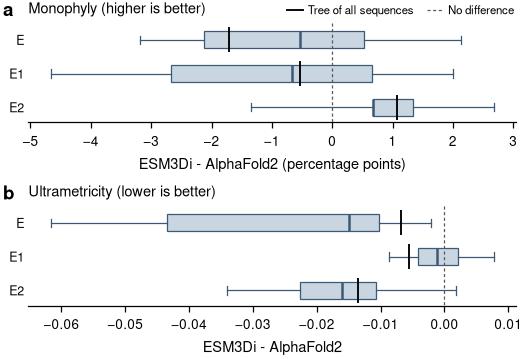

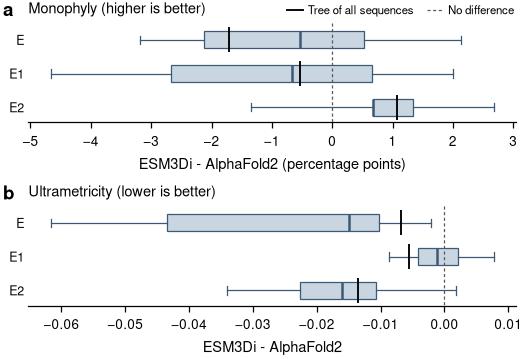

In [6]:
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

sys.path.insert(0, "../../../benchmarks")   # the shared figure style
from pub_style import MM, MUTED_TEXT, WIDTH_SINGLE, save_pub, use_pub_style

use_pub_style()

BOX_COLOUR = "#3C5A75"
WHISKERS = (2.5, 97.5)      # the whiskers span 95% of the replicates
FULL_HALF = 0.37            # half-height of the mark for the tree of all sequences; the box is 0.25
# measure, factor onto the units of the axis, axis label. The direction of each measure is in its
# title: it differs between the two, which is the one thing a difference axis cannot show by itself.
PANELS = [("Monophyly (higher is better)", "fraction", 100, "ESM3Di - AlphaFold2 (percentage points)"),
          ("Ultrametricity (lower is better)", "root_to_tip_cv", 1, "ESM3Di - AlphaFold2")]

summary = jackknife_summary.set_index(["protein", "measure"])
fig = plt.figure(figsize=(WIDTH_SINGLE, 62 * MM), layout="constrained")
axes = fig.subplots(len(PANELS), 1)

for ax, (title, measure, factor, xlabel) in zip(axes, PANELS):
    differences, full = [], []
    for name in DATASETS.values():
        paired = replicates[replicates["dataset"] == name].pivot(index="replicate", columns="method", values=measure)
        differences.append(factor * (paired["ESM3Di"] - paired["AlphaFold2"]).to_numpy())
        scores = summary.loc[(name, measure)]
        full.append(factor * (scores["full ESM3Di"] - scores["full AlphaFold2"]))

    # no difference: over the rows only, and above the boxes, so that the boxes do not hide parts of
    # it and it is drawn the same in both panels
    ax.plot([0, 0], [-0.5, len(differences) - 0.55], color=MUTED_TEXT, lw=0.6, ls=(0, (2.5, 2)), zorder=6)
    ax.boxplot(differences, positions=range(len(differences)), vert=False, widths=0.5, whis=WHISKERS,
               showfliers=False, patch_artist=True, zorder=3,
               boxprops=dict(facecolor="#C9D6E1", edgecolor=BOX_COLOUR, linewidth=0.6),
               medianprops=dict(color=BOX_COLOUR, linewidth=1.2),
               whiskerprops=dict(color=BOX_COLOUR, linewidth=0.6),
               capprops=dict(color=BOX_COLOUR, linewidth=0.6))

    # where the difference of the trees of all sequences falls among the replicates; taller than the
    # box, so it is not taken for the median line inside it
    for row, difference in enumerate(full):
        ax.plot([difference, difference], [row - FULL_HALF, row + FULL_HALF], color="black", lw=0.9,
                solid_capstyle="butt", zorder=5)
    ax.set_ylim(len(differences) - 0.55, -0.6)
    ax.set_yticks(range(len(differences)), DATASETS.values(), fontsize=6)
    ax.tick_params(axis="y", length=0, pad=2)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", pad=3)

# A key for the two marks, on the title line of the first panel, where it covers nothing
axes[0].legend(handles=[Line2D([], [], color="black", lw=0.9, label="Tree of all sequences"),
                        Line2D([], [], color=MUTED_TEXT, lw=0.6, ls=(0, (2.5, 2)), label="No difference")],
               loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2, frameon=False, fontsize=5.5,
               handlelength=1.4, handletextpad=0.4, columnspacing=1.2, borderpad=0, borderaxespad=0.2)

fig.canvas.draw()
fig.set_layout_engine("none")
for ax, letter in zip(axes, "ab"):
    box = ax.get_tightbbox().transformed(fig.transFigure.inverted())
    fig.text(0, box.y1, letter, fontsize=9, fontweight="bold", ha="left", va="top")

save_pub(fig, "flaviviridae_jackknife_difference", "figures")
fig